### Introduction & Goals

This notebook has the objective to clean the clientes dataset (`clientes.csv`) before it is joined with the train dataset (`train.csv`) and the test dataset (`test.csv`) through `customer_id`. We identify and handle the structural missing values and check for anomalous or implausible observations.

In this notebook we:
1. remove the column `customer_type`, because it has no values at all;
2. separate the columns that identify a customer instead of describing it;
3. fill the structural missing values of the geographic columns with `"(foreign)"` and `"(mainland)"`;
4. create the flag `since_2015_or_earlier`, because the year 2015 probably groups all the customers that joined in 2015 or before;
5. check `customer_since_year` for outliers, summarize the changes and save `clientes_clean.csv`.

All these steps are fixed rules applied row by row, so we do not learn anything from the data and nothing from `test.csv` can leak into the cleaning. The steps that need to learn from the data (filling the other missing values, encoding and scaling) are done in the merge notebook, only with the training rows of each split.

**Notebook index**

| Section | Action | Output file |
|---|---|---|
| 1 | Load `clientes.csv` (1,143 customers, 13 columns) | – (no file written) |
| 2.1 | Drop `customer_type`, which has no values | – (no file written) |
| 2.2 | Separate the key, the identifier-like columns (kept for future reference), the numeric and the categorical features | – (no file written) |
| 2.3 | Structural missing values: show that `island` is missing only outside the island regions, then fill with `"(foreign)"` / `"(mainland)"` | – (no file written) |
| 2.4 | `customer_since_year`: domain check against `train.csv` and `since_2015_or_earlier` flag | – (no file written) |
| 2.5 | Outlier check on `customer_since_year` (no treatment needed) | – (no file written) |
| 2.6 | Cleaning summary and saving of the cleaned table | `clientes_clean.csv` |

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


---

### 1. Data Loading

In [2]:
clientFile = "../../../data/clientes.csv"
raw = pd.read_csv(clientFile)

print(f"{raw.shape[0]:,} customers (one row each) x {raw.shape[1]} columns")
raw.head()

1,143 customers (one row each) x 13 columns


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


---

### 2.1. Data Cleaning: Dropping the Fully Empty Column
We identified in the previous notebook that the column `customer_type` has 0 non-missing values out of 1,143 customers, so it is a completely empty column. Because it provides no predictive signal, it was removed from the customer dataset.

In [3]:
df_clean = raw.copy()

# 1. Remove the fully empty column
df_clean = df_clean.drop(columns=["customer_type"])

# 2. Verification of the removal of the column
print(f"rows (customers): {raw.shape[0]:,} -> {df_clean.shape[0]:,}")
print(f"columns:          {raw.shape[1]} -> {df_clean.shape[1]}")

rows (customers): 1,143 -> 1,143
columns:          13 -> 12


**Conclusions:** Because this column doesn't have any values, it doesn't provide any predictive signal, so we decided that it was best to remove it before we join the clientes dataset with `train.csv` and `test.csv`. As we can see in the output of this cell, the number of columns of the dataset decreases from 13 to 12, and all the 1,143 customers are kept.

---

### 2.2. Feature Type Separation & Exclusions
To prepare the customer table for the merge with `train.csv`/`test.csv` and for feature encoding, we divide its attributes into distinct functional groups:

1. **Identifiers (`identifiers`):**
   * The customer key (`customer_id`) is kept in the table because it is the join key with `train.csv`/`test.csv`, but it is never used as a predictor, to prevent *overfitting*.
   * **Identifier-like columns (`id_like`):** columns whose values are distinct for more than 80% of the customers that have a value. They name a customer instead of describing one. Here they are only presented and separated from the features, and they stay in the file for future reference: how the identifier-like variables are treated is decided in the feature selection notebook.
2. **Numeric Features (`numeric`):**
   * Dynamically selected numerical indicators. In this table this is only `customer_since_year`, which is used as it is and only scaled later, inside each train split (see 2.4).

3. **Categorical Features (`categorical`):**
   * Dynamically identified non-numeric attributes (the geographic hierarchy: `country_or_region`, `commercial_region`, `island`, `municipality`, `city`, `postal_area`), designated for missing value imputation and one-hot encoding (with the rare levels grouped), both fitted in the merge on the training rows.

In [4]:
# Identifiers
key = "customer_id"

# Id-like columns.
cardinality = pd.DataFrame({
    "filled": df_clean.notna().sum(),
    "distinct": df_clean.nunique(),
}).drop(index=key)
cardinality["distinct % of filled"] = (cardinality["distinct"] / cardinality["filled"] * 100).round(1)
cardinality = cardinality.sort_values("distinct % of filled", ascending=False)

id_like = cardinality.index[cardinality["distinct % of filled"] > 80].tolist()
identifiers = [key] + id_like

# Numeric columns
numeric = [
    c for c in df_clean.columns
    if c not in identifiers and pd.api.types.is_numeric_dtype(df_clean[c])
]

# Categorical columns
categorical = [
    c for c in df_clean.columns
    if c not in identifiers + numeric
]

print("identifier-like:", id_like)
print("numeric:", numeric)
print("categorical:", categorical)
cardinality

identifier-like: ['company_name', 'address', 'street', 'postal_code']
numeric: ['customer_since_year']
categorical: ['country_or_region', 'commercial_region', 'island', 'municipality', 'city', 'postal_area']


,filled,distinct,distinct % of filled
company_name,1143,1141,99.8
address,1137,1120,98.5
street,545,511,93.8
postal_code,973,828,85.1
city,597,417,69.8
postal_area,1072,271,25.3
municipality,984,183,18.6
commercial_region,1029,37,3.6
island,565,10,1.8
country_or_region,1143,11,1.0


**Conclusions:** `company_name` (99.8%), `address` (98.5%), `street` (93.8%) and `postal_code` (85.1%) have a different value for almost every customer that has one, so they name a customer instead of describing one. We separate them from the features and keep them in the file for future reference, because the identifier-like variables are treated in the feature selection notebook. `city` (69.8%) is below the 80% threshold, so here it stays with the categorical features, but its large number of levels is also analysed in the feature selection. The table is now divided into 1 key (`customer_id`), 4 identifier-like columns, 1 numeric feature (`customer_since_year`) and 6 categorical features.

---

### 2.3. Handling Structural Missing Values



#### 2.3.1. Structural Missing Values in `island`
A missing value is structural when the value does not exist for that customer, instead of being lost. To check this for `island`, we compare where the customers with and without an island are: abroad (foreign), in the island regions of CT10 (RG17 and RG29), in the other regions of CT10, or in CT10 without a region.

In [5]:
# Where each customer is.
is_ct10 = df_clean["country_or_region"].str.startswith("Country CT10:")
where = pd.Series(np.select(
    [~is_ct10,
     df_clean["commercial_region"].isna(),
     df_clean["commercial_region"].str.startswith(("Region RG17:", "Region RG29:"), na=False)],
    ["foreign", "CT10, no region", "CT10, island region (RG17/RG29)"],
    default="CT10, other region"), index=df_clean.index, name="where the customer is")

# island is recorded only for the customers of the island regions (RG17 and RG29)
print("regions of the customers with an island:",
      sorted(df_clean.loc[df_clean["island"].notna(), "commercial_region"].unique()))
pd.crosstab(where, df_clean["island"].isna().map({False: "island filled", True: "island missing"}),
            margins=True)

regions of the customers with an island: ['Region RG17: We Will See Later', 'Region RG29: We Will See Later']


island,island filled,island missing,All
where the customer is,,,
"CT10, island region (RG17/RG29)",565,0,565
"CT10, no region",0,95,95
"CT10, other region",0,419,419
foreign,0,64,64
All,565,578,1143


**Conclusions:** `island` is filled for all 565 customers of the two island regions (RG17 and RG29) and missing for every other customer: the 419 CT10 customers in mainland regions, the 64 foreign customers and the 95 CT10 customers without a region. Only RG17 and RG29 have islands, so the missing values are not random: these customers are not on an island, so the value does not exist for them. This is why the missing values in `island` are **structural**. The 95 customers without a region are the exception: without the region we cannot know if they are on an island, so they are left open. The same happens with `municipality` and `postal_area` for the 64 foreign customers: they are divisions of CT10, and the exploration notebook (section 1.3.2) showed that they are missing for every customer outside CT10.

#### 2.3.2. Filling the Structural Missing Values
As shown in 2.3.1, these values do not exist for the customers below, so they are filled with an explicit category instead of being imputed:

* **Foreign customers** (outside CT10) have no `island`, `municipality` or `postal_area`, since these are CT10 divisions → `"(foreign)"`.
* **CT10 customers in a non-island region** (every region except RG17 and RG29) have no `island` → `"(mainland)"`.

The labels are written in parentheses, following the convention used in the course practicals (the "own level"
fill uses `"(missing)"`): it marks them as categories created during cleaning rather than values that came with the
data, and guarantees they can never coincide with a real level such as `"Island IS7: The Pivot Archipelago"`.

Since this is a fixed rule and not a statistic computed from the rows (like a mode or a median), it cannot leak
information from future test rows, so it is applied to the cleaned file. The 95 CT10 customers with no
`commercial_region` are **not** filled: without the region we cannot tell whether the island is absent or simply
unrecorded, so their `island` and `municipality` stay missing and are handled inside each train split.

In [6]:
# Structural rules: a cell is filled only if it is empty AND the rule says the value cannot exist
foreign = ~df_clean["country_or_region"].str.startswith("Country CT10:")
island_region = df_clean["commercial_region"].str.startswith(
    ("Region RG17:", "Region RG29:"), na=False
)
mainland = ~foreign & df_clean["commercial_region"].notna() & ~island_region

structural_rules = [
    # (rows, columns, label)
    (foreign,  ["island", "municipality", "postal_area"], "(foreign)"),
    (mainland, ["island"],"(mainland)"),
]

nulls_before = df_clean.isna().sum()
for rows, cols, label in structural_rules:
    for col in cols:
        df_clean.loc[rows & df_clean[col].isna(), col] = label

filled = nulls_before - df_clean.isna().sum()
pd.DataFrame({
    "nulls before": nulls_before,
    "filled (structural)": filled,
    "nulls left": df_clean.isna().sum(),
}).loc[lambda t: t["nulls before"] > 0]

,nulls before,filled (structural),nulls left
commercial_region,114,0,114
island,578,483,95
municipality,159,64,95
city,546,0,546
postal_area,71,64,7
postal_code,170,0,170
street,598,0,598
address,6,0,6


**Conclusions:** As we can see in the table, the rules fill 483 values of `island` (419 with `"(mainland)"` and 64 with `"(foreign)"`), 64 of `municipality` and 64 of `postal_area`, and no other column is changed. The values that stay missing are the ones the rules cannot decide: the `island` and `municipality` of the 95 CT10 customers without a region, and 7 values of `postal_area` of CT10 customers, where the postal area exists but was not recorded.

---

### 2.4. `customer_since_year`: a Censored Year
`customer_since_year` is the only numeric feature of this table. Before it is used, two questions: is every value
**possible** (domain check), and does every value **mean what it says**?

In [7]:
# The purchase history only starts in mid-2015: nothing earlier can be observed.
# Only train.csv is read: test.csv is never used to make cleaning decisions.
train_dates = pd.read_csv("../../../data/train.csv", usecols=["customer_id", "purchase_date"],
                          parse_dates=["purchase_date"])

pd.DataFrame({
    "first purchase": [train_dates["purchase_date"].min()],
    "last purchase": [train_dates["purchase_date"].max()],
}, index=["train.csv"])

,first purchase,last purchase
train.csv,2015-07-11,2025-02-15


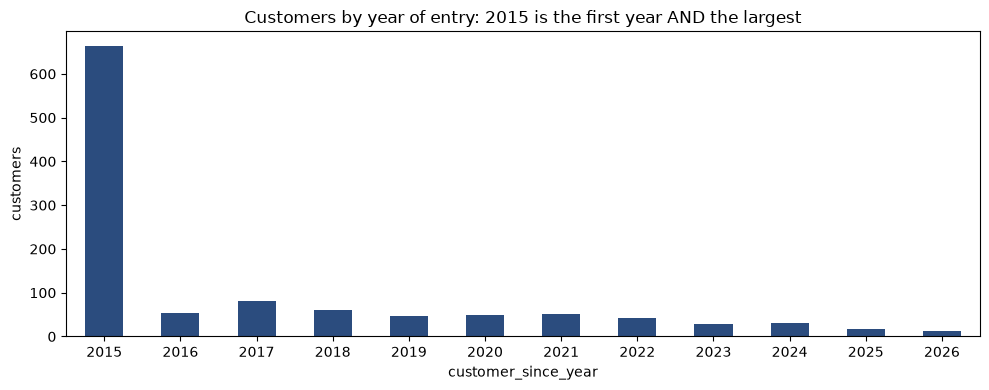

2015: 664 customers (58.1%); every other year: 13 to 82


In [8]:
# How many customers joined in each year
since_counts = df_clean["customer_since_year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
since_counts.plot(kind="bar", color="#2b4c7e", ax=ax)
ax.set(xlabel="customer_since_year", ylabel="customers",
       title="Customers by year of entry: 2015 is the first year AND the largest")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"2015: {since_counts[2015]} customers ({since_counts[2015] / len(df_clean):.1%}); "
      f"every other year: {since_counts.drop(2015).min()} to {since_counts.drop(2015).max()}")

In [9]:
# Year of each customer's first purchase in train.csv, against the year they joined
first_year = train_dates.groupby("customer_id")["purchase_date"].min().dt.year.rename("first_purchase_year")
since_vs_first = df_clean[["customer_id", "customer_since_year"]].merge(
    first_year, on="customer_id", how="left")

# Domain check: a customer cannot buy before joining
assert (since_vs_first["first_purchase_year"].dropna()
        >= since_vs_first.loc[since_vs_first["first_purchase_year"].notna(), "customer_since_year"]).all()
print("Domain check passed: no first purchase before customer_since_year")

# Share of customers whose first purchase comes 2 or more years after joining
with_purchases = since_vs_first.dropna(subset=["first_purchase_year"])
late_start = (with_purchases["first_purchase_year"] - with_purchases["customer_since_year"]) >= 2
print(f"first purchase 2+ years after joining: "
      f"{late_start[with_purchases['customer_since_year'] == 2015].sum()} customers from 2015, "
      f"{late_start[with_purchases['customer_since_year'] > 2015].sum()} from all later years together")
print(f"customers with no purchase in train.csv: {since_vs_first['first_purchase_year'].isna().sum()}")

pd.crosstab(since_vs_first["customer_since_year"],
            since_vs_first["first_purchase_year"].astype("Int64"))

Domain check passed: no first purchase before customer_since_year
first purchase 2+ years after joining: 51 customers from 2015, 9 from all later years together
customers with no purchase in train.csv: 536


first_purchase_year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
customer_since_year,,,,,,,,,,,
2015,161,26,15,13,5,7,5,4,1,1,0
2016,0,25,22,0,0,1,0,0,1,0,0
2017,0,0,40,33,0,0,0,0,0,0,1
2018,0,0,0,36,8,1,0,1,0,0,0
2019,0,0,0,0,23,13,0,0,0,0,0
2020,0,0,0,0,0,27,12,1,0,0,0
2021,0,0,0,0,0,0,34,8,1,0,1
2022,0,0,0,0,0,0,0,29,9,1,0
2023,0,0,0,0,0,0,0,0,19,5,0


**Conclusions:** Every value is possible (no customer buys before joining). Only `train.csv` is used here, so no
information from the test set enters a cleaning decision, but **2015 does not mean what it says**:

* The purchase history in `train.csv` only starts in **July 2015**, so 2015 is the first year the records can show.
* 2015 holds **58%** of the customers (664 of 1,143), against 13 to 82 in every other year: a real year of entry
  spreads out, a code piles up on one value.
* For customers who joined from 2016 on, the first purchase is almost always in the year they joined or the next.
  For 2015 the first purchase spreads up to 2024: 51 customers start buying 2 or more years after "joining".

2015 most likely groups every customer who joined **before the records start** (a *left-censored* value: the true
year is cut off at the lower limit of the data), possibly together with customers whose year was unknown. This is a
hypothesis, not a fact, but either way 2015 is not a reliable year of entry.

The value is kept, and a binary flag `since_2015_or_earlier` is added so the model can tell these customers apart.
A flag is a fixed rule computed row by row, so it fits nothing and cannot leak. `customer_since_year` is **not**
log-transformed: log1p is meant for long right-tailed amounts, and on a year it only maps 2015-2026 to 7.609-7.614.
Scaling, if needed, is fitted inside each train split together with the encoding.

In [10]:
df_clean["since_2015_or_earlier"] = (df_clean["customer_since_year"] == 2015).astype(int)
df_clean["since_2015_or_earlier"].value_counts()

since_2015_or_earlier
1    664
0    479
Name: count, dtype: int64

---

### 2.5. Outliers
The usual outlier rule (1.5 x IQR) assumes a distribution with a middle. `customer_since_year` has no middle: more than
half of its values are exactly 2015.

**Conclusions:** No outlier treatment is applied to this table.

---

### 2.6. Saving the Cleaned Dataset
The cleaned table is saved at the end, once every cleaning step above has been applied.

**What the file carries forward to the modelling stage**, left open here and handled in the next notebooks:

* **Identifier-like columns kept for future reference.** `company_name`, `address`, `street` and `postal_code` stay in
  the file (as identifiers do in the course practicals), separated from the features in 2.2: how they are treated is
  decided in the feature selection notebook. `customer_id` is only the join key with `train.csv`/`test.csv` and is
  never used as a predictor.
* **Remaining missing values left open.** `city`, `street`, `postal_code`, `commercial_region`, the `island` and
  `municipality` of the 95 CT10 customers with no region and the few gaps in `postal_area`/`address` are not filled
  here: a mode computed on this file would include the customers of future test rows. After the merge, the candidate
  fills for these labels (the mode, an own `"(missing)"` level, or a label drawn in the training shares) are compared
  by AP on the same 7 temporal splits (each one trains on the past and validates on the period after it), and the
  winner, the mode, is fitted on the training rows of each split only.
* **Encoding and scaling** are also fitted inside each split, after the merge (see the cardinality analysis in 2.2).
* **Geographic hierarchy kept whole.** `country_or_region`, `commercial_region`, `island`, `municipality`, `city` and
  `postal_area` describe the same location at different levels, so they overlap (see section 1.7.1 of the
  exploration notebook). All of them stay in the file as candidates, and the feature selection notebook decides which
  levels the model keeps.

**Cleaning summary.** What this notebook changed before the file is saved: the rows, the columns, and the gaps of every column.

In [11]:
# What the cleaning changed: rows, columns, and the gaps filled by a rule or left for the merge
print(f"rows: {len(raw):,} -> {len(df_clean):,}")
print("columns removed:", sorted(set(raw.columns) - set(df_clean.columns)),
      "| columns added:", sorted(set(df_clean.columns) - set(raw.columns)))

kept = [c for c in raw.columns if c in df_clean.columns]
gaps = pd.DataFrame({
    "missing before": raw[kept].isna().sum(),
    "filled by a rule": raw[kept].isna().sum() - df_clean[kept].isna().sum(),
    "left for the merge": df_clean[kept].isna().sum(),
})
gaps = gaps[gaps["missing before"] > 0]
gaps.loc["total"] = gaps.sum()
gaps

rows: 1,143 -> 1,143
columns removed: ['customer_type'] | columns added: ['since_2015_or_earlier']


,missing before,filled by a rule,left for the merge
commercial_region,114,0,114
island,578,483,95
municipality,159,64,95
city,546,0,546
postal_area,71,64,7
postal_code,170,0,170
street,598,0,598
address,6,0,6
total,2242,611,1631


**Conclusions:** No customer is removed, so every purchase in `train.csv` still finds its customer (checked in 2.5). One column is removed (`customer_type`) and one is added (`since_2015_or_earlier`). The fixed rules fill 611 structural gaps (483 in `island`, 64 in `municipality` and 64 in `postal_area`); the other 1,631 gaps stay open and are filled in the merge, with values learned on the training rows only.

In [12]:
outputFile = "../../../data/clientesDataset/clientes_clean.csv"
df_clean.to_csv(outputFile, index=False)

print(f"Dataset cleaned saved successfully to: {outputFile}")
print(f"{df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns, "
      f"{df_clean.isna().sum().sum():,} missing values left open")

Dataset cleaned saved successfully to: ../../../data/clientesDataset/clientes_clean.csv
1,143 rows x 13 columns, 1,631 missing values left open


---
**Next:** [Pre-processing – Merge & Pre-processing](../../2_Pre-processing/1_Merge%26Preprocessing.ipynb)